In [10]:
%pip install torch transformers pillow

  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.5/138.5 MB 39.2 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 40.0 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 23.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 35.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 35.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 38.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 42.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 35.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 42.8 MB/s  0:00:00
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 35.6 MB/s  0:00:00
Using cached mdurl-0.1.2-py3-none-any.whl (10

In [17]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 39.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 45.3 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))

In [5]:
import pandas as pd
from classify import classify_garment

df = pd.read_csv(ROOT / "data/escvdo_all.csv")

mapa = {
    "top": "tops", "shirt": "tops",
    "pants": "bottoms", "skirt": "bottoms",
    "dress": "dresses",
    "sweater": "knitwear",
    "blazer": "outerwear", "coat": "outerwear",
}
df["truth"] = df["category"].map(mapa)

results = [classify_garment(ROOT / "images" / r.folder / r.file)
           for r in df.itertuples()]
df["garment"] = [r[0] for r in results]
df["confidence"] = [r[1] for r in results]

print(f"Acierto: {(df['truth'] == df['garment']).mean():.0%}")
pd.crosstab(df["truth"], df["garment"])

Acierto: 42%


garment,bottoms,dresses,knitwear,tops
truth,,,,
bottoms,2,10,3,0
dresses,1,16,2,0
knitwear,0,0,1,0
outerwear,0,1,1,0
tops,2,7,3,3


In [6]:
import pandas as pd
from classify import classify_garment

escvdo = pd.read_csv(ROOT / "data/escvdo_all.csv")
chloe = pd.read_csv(ROOT / "data/chloe_all.csv")
all_df = pd.concat([escvdo, chloe], ignore_index=True)

results = [classify_garment(ROOT / "images" / r.folder / r.file)
           for r in all_df.itertuples()]
all_df["garment"] = [r[0] for r in results]
all_df["confidence"] = [r[1] for r in results]

all_df.to_csv(ROOT / "data/classified.csv", index=False)
pd.crosstab(all_df["brand"], all_df["garment"], normalize="index").round(2)

garment,bottoms,dresses,knitwear,outerwear,tops
brand,,,,,
chloe,0.1,0.48,0.05,0.27,0.10
escvdo,0.1,0.65,0.19,0.00,0.06


In [7]:
import pandas as pd
# run just one time
escvdo = pd.read_csv(ROOT / "data/escvdo_all.csv")
tpl = escvdo[["folder", "file", "name", "category"]].copy()
tpl["labels_manual"] = ""
tpl.to_csv(ROOT / "data/escvdo_labels.csv", index=False)
print(len(tpl))

52


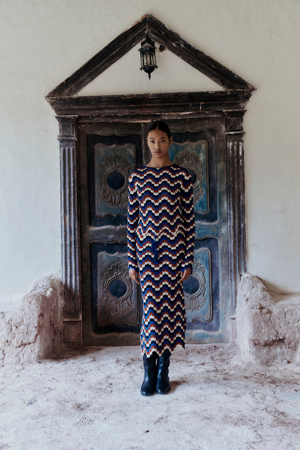

10/52 | SAFI MIDI SKIRT | por nombre: skirt


In [14]:
import pandas as pd
from IPython.display import display, clear_output
from PIL import Image

KEYS = {"t": "tops", "b": "bottoms", "d": "dresses", "k": "knitwear", "o": "outerwear"}
path = ROOT / "data/escvdo_labels_FINAL.csv"

if not path.exists():                       # solo se crea la primera vez
    e = pd.read_csv(ROOT / "data/escvdo_all.csv")
    tpl = e[["folder", "file", "name", "category"]].copy()
    tpl["labels_manual"] = ""
    tpl.to_csv(path, index=False)

tpl = pd.read_csv(path)
tpl["labels_manual"] = tpl["labels_manual"].fillna("")

for i, r in tpl.iterrows():
    if r["labels_manual"]:
        continue                            # ya etiquetada
    img = Image.open(ROOT / "images" / r["folder"] / r["file"]).convert("RGB")
    img.thumbnail((450, 450))
    clear_output(wait=True)
    display(img)
    print(f"{i + 1}/{len(tpl)} | {r['name']} | por nombre: {r['category']}")
    ans = input("t=tops b=bottoms d=dresses k=knitwear o=outerwear (ej: kb) | s=salir > ")
    if ans == "s":
        break
    tpl.at[i, "labels_manual"] = "|".join(KEYS[c] for c in ans if c in KEYS)
    tpl.to_csv(path, index=False)           # guarda en cada foto


In [15]:
import pandas as pd

t = pd.read_csv(ROOT / "data/escvdo_labels_FINAL.csv")
t["labels_manual"] = t["labels_manual"].fillna("")
print(t["labels_manual"].ne("").sum(), "de", len(t), "etiquetadas")

t.to_csv(ROOT / "data/escvdo_labels_BACKUP.csv", index=False)   # copia de seguridad

pred = pd.read_csv(ROOT / "data/classified.csv")[["folder", "file", "garment"]]
m = t.merge(pred, on=["folder", "file"])
m["hit"] = [g in l.split("|") for g, l in zip(m["garment"], m["labels_manual"])]

print(f"Acierto de CLIP: {m['hit'].mean():.0%}")
print("\nComposición real de ESCVDO:")
print(m["labels_manual"].str.split("|").explode().value_counts())

52 de 52 etiquetadas
Acierto de CLIP: 56%

Composición real de ESCVDO:
labels_manual
knitwear     48
dresses      19
tops         15
bottoms      15
outerwear     3
Name: count, dtype: int64


In [16]:
import numpy as np
import pandas as pd
from classify import get_embedding

labels = pd.read_csv(ROOT / "data/escvdo_labels_FINAL.csv")

X = np.array([get_embedding(ROOT / "images" / r.folder / r.file)
              for r in labels.itertuples()])
np.save(ROOT / "data/escvdo_embeddings.npy", X)
print(X.shape)

(52, 512)


In [18]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score

labels = pd.read_csv(ROOT / "data/escvdo_labels_FINAL.csv")
labels["labels_manual"] = labels["labels_manual"].fillna("")
X = np.load(ROOT / "data/escvdo_embeddings.npy")

classes = ["tops", "bottoms", "dresses", "knitwear"]
Y = np.array([[c in l.split("|") for c in classes]
              for l in labels["labels_manual"]]).astype(int)

# entrenar y probar con fotos que el modelo no vio (5 vueltas)
P = np.zeros(Y.shape)
for train, test in KFold(5, shuffle=True, random_state=0).split(X):
    for j in range(len(classes)):
        y = Y[train, j]
        if y.min() == y.max():
            P[test, j] = y[0]
        else:
            clf = LogisticRegression(C=10, max_iter=1000, class_weight="balanced")
            clf.fit(X[train], y)
            P[test, j] = clf.predict_proba(X[test])[:, 1]

# CLIP puro (lo que ya clasificamos)
pred = pd.read_csv(ROOT / "data/classified.csv")[["folder", "file", "garment"]]
clip = labels.merge(pred, on=["folder", "file"], how="left")["garment"]
C = np.array([[g == c for c in classes] for g in clip]).astype(int)

res = pd.DataFrame({
    "clip_puro": [f1_score(Y[:, j], C[:, j], zero_division=0) for j in range(4)],
    "modelo_entrenado": [f1_score(Y[:, j], P[:, j] > 0.5, zero_division=0) for j in range(4)],
}, index=classes).round(2)
res

,clip_puro,modelo_entrenado
tops,0.33,0.41
bottoms,0.20,0.12
dresses,0.60,0.57
knitwear,0.28,0.93


black (10, 21, 38)


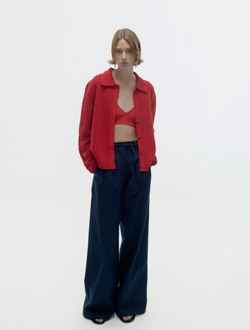

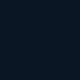

In [2]:
from colors import dominant_color
from IPython.display import display
from PIL import Image

path = ROOT / "images/escvdo_ss26/001.png"   # cambia por una foto que exista
name, rgb = dominant_color(path)
print(name, rgb)
display(Image.open(path).resize((250, 330)))
display(Image.new("RGB", (80, 80), rgb))

In [5]:
import pandas as pd
from colors import dominant_color

escvdo = pd.read_csv(ROOT / "data/escvdo_all.csv")
chloe = pd.read_csv(ROOT / "data/chloe_all.csv")
df = pd.concat([escvdo, chloe], ignore_index=True)

upper, lower = [], []
for r in df.itertuples():
    p = ROOT / "images" / r.folder / r.file
    upper.append(dominant_color(p, region="upper")[0])
    lower.append(dominant_color(p, region="lower")[0])

df["color_upper"] = upper
df["color_lower"] = lower
df.to_csv(ROOT / "data/colors.csv", index=False)

pd.crosstab(df["brand"], df["color_upper"], normalize="index").round(2)

color_upper,beige,black,brown,grey,pink,red,yellow
brand,,,,,,,
chloe,0.78,0.10,0.02,0.02,0.05,0.02,0.02
escvdo,0.35,0.27,0.12,0.23,0.04,0.00,0.00


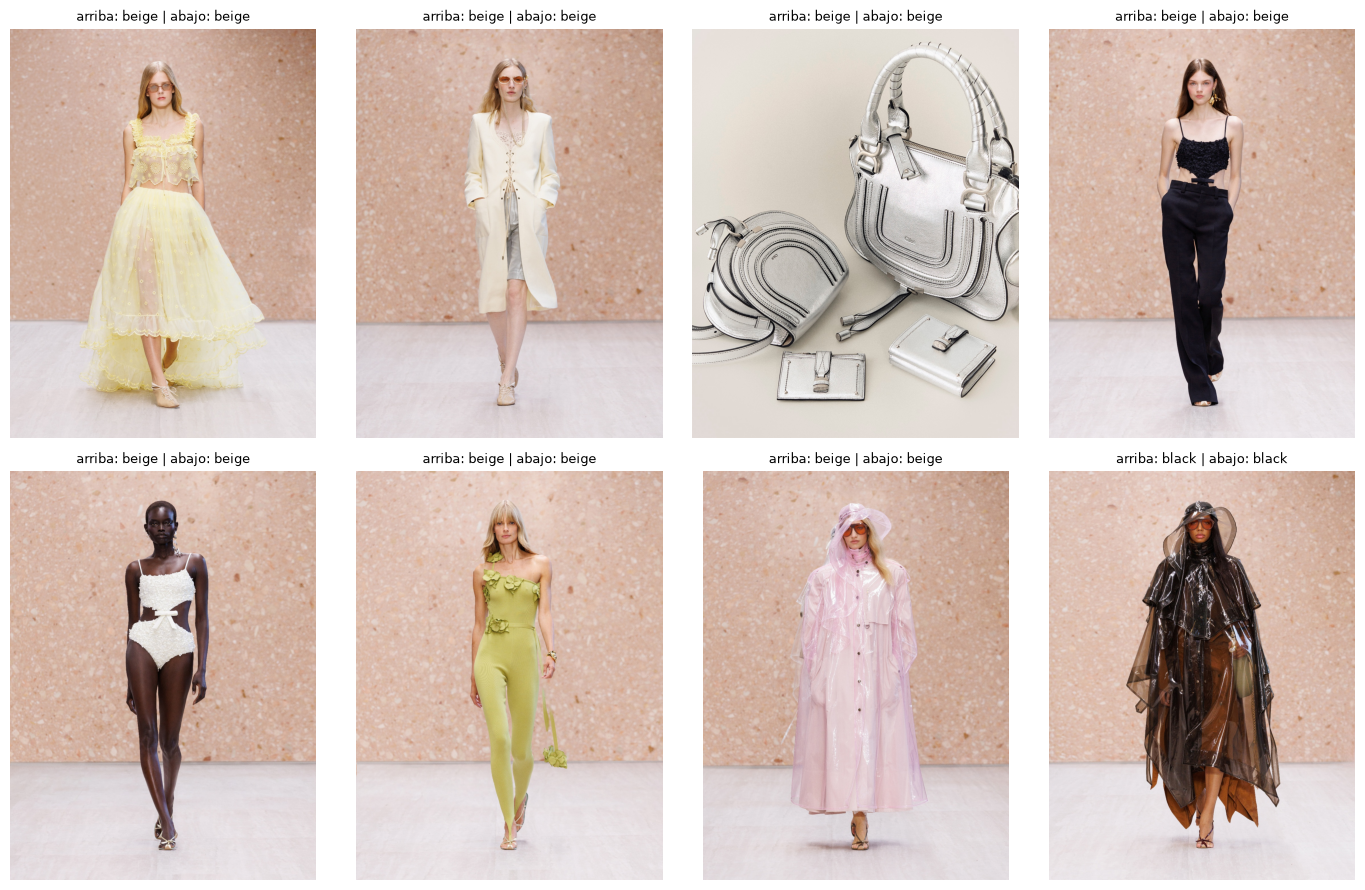

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

c = pd.read_csv(ROOT / "data/colors.csv")
c = c[c["brand"] == "chloe"].sample(8, random_state=1)

fig, axes = plt.subplots(2, 4, figsize=(14, 9))
for ax, r in zip(axes.flat, c.itertuples()):
    ax.imshow(Image.open(ROOT / "images" / r.folder / r.file).convert("RGB"))
    ax.set_title(f"arriba: {r.color_upper} | abajo: {r.color_lower}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

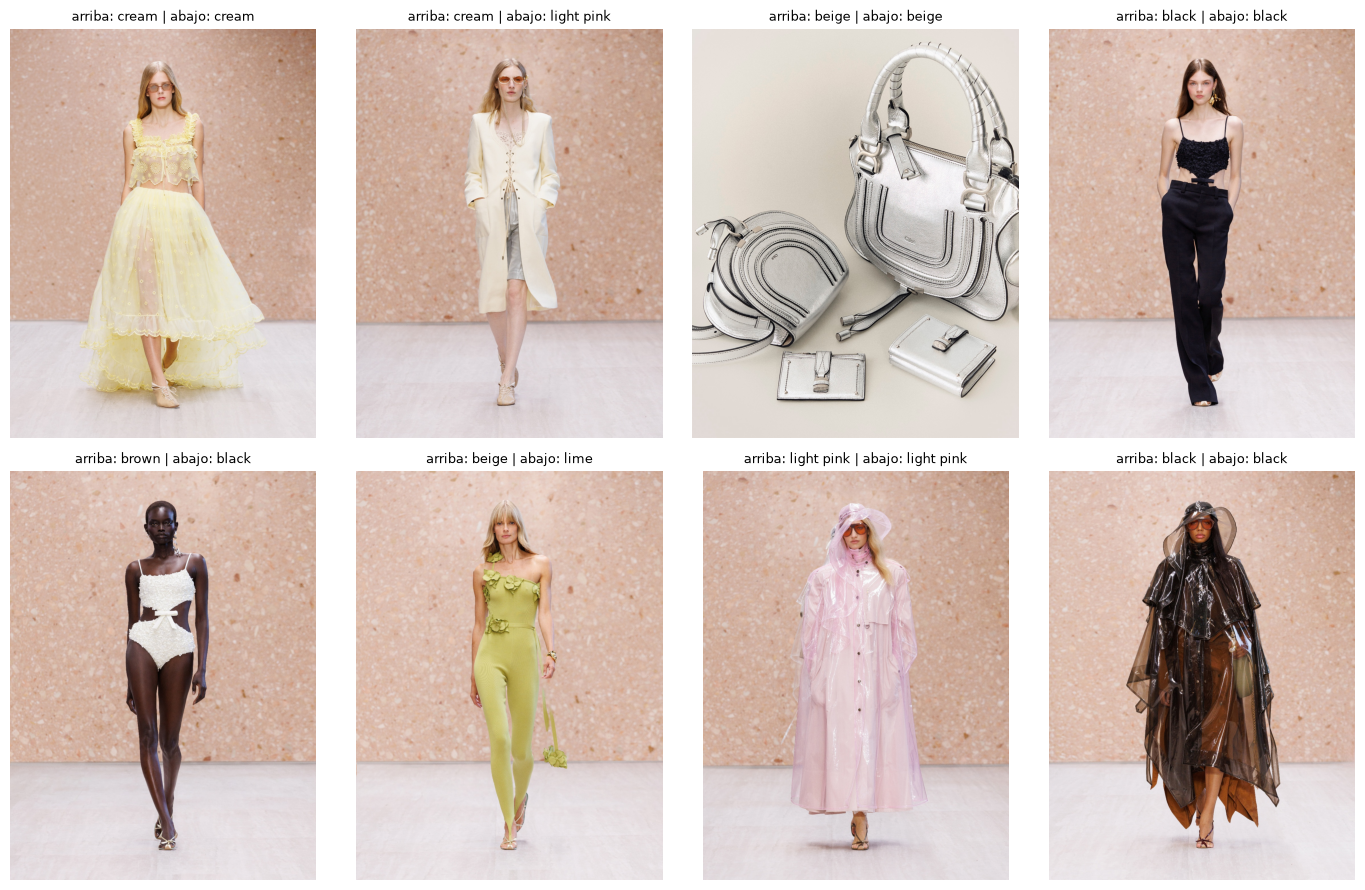

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from colors import dominant_color

c = pd.read_csv(ROOT / "data/chloe_all.csv").sample(8, random_state=1)
fig, axes = plt.subplots(2, 4, figsize=(14, 9))
for ax, r in zip(axes.flat, c.itertuples()):
    p = ROOT / "images" / r.folder / r.file
    ax.imshow(Image.open(p).convert("RGB"))
    ax.set_title(f"arriba: {dominant_color(p, region='upper')[0]} | abajo: {dominant_color(p, region='lower')[0]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [3]:
import pandas as pd
from colors import dominant_color

escvdo = pd.read_csv(ROOT / "data/escvdo_all.csv")
chloe = pd.read_csv(ROOT / "data/chloe_all.csv")
df = pd.concat([escvdo, chloe], ignore_index=True)

upper, lower = [], []
for r in df.itertuples():
    p = ROOT / "images" / r.folder / r.file
    upper.append(dominant_color(p, region="upper")[0])
    lower.append(dominant_color(p, region="lower")[0])

df["color_upper"] = upper
df["color_lower"] = lower
df.to_csv(ROOT / "data/colors.csv", index=False)

pd.crosstab(df["brand"], df["color_upper"], normalize="index").round(2)

color_upper,beige,black,brown,cream,grey,light pink,navy,orange,red,white,yellow
brand,,,,,,,,,,,
chloe,0.08,0.23,0.03,0.03,0.07,0.18,0.02,0.02,0.03,0.27,0.03
escvdo,0.19,0.23,0.15,0.00,0.23,0.12,0.02,0.04,0.02,0.00,0.00


In [2]:
import pandas as pd
from classify import classify_pattern

df = pd.read_csv(ROOT / "data/colors.csv")

res = [classify_pattern(ROOT / "images" / r.folder / r.file)
       for r in df.itertuples()]
df["pattern"] = [r[0] for r in res]
df["pattern_conf"] = [r[1] for r in res]

df.to_csv(ROOT / "data/attributes.csv", index=False)
pd.crosstab(df["brand"], df["pattern"], normalize="index").round(2)

/Users/gloriamorales/Documents/Agent_AI/escvdo-trend-agent/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1115 23:38:07.159000 56060 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 28119.34it/s]


pattern,animal print,checked,floral,polka dots,solid,striped
brand,,,,,,
chloe,0.10,0.00,0.23,0.08,0.48,0.10
escvdo,0.12,0.02,0.08,0.12,0.21,0.46


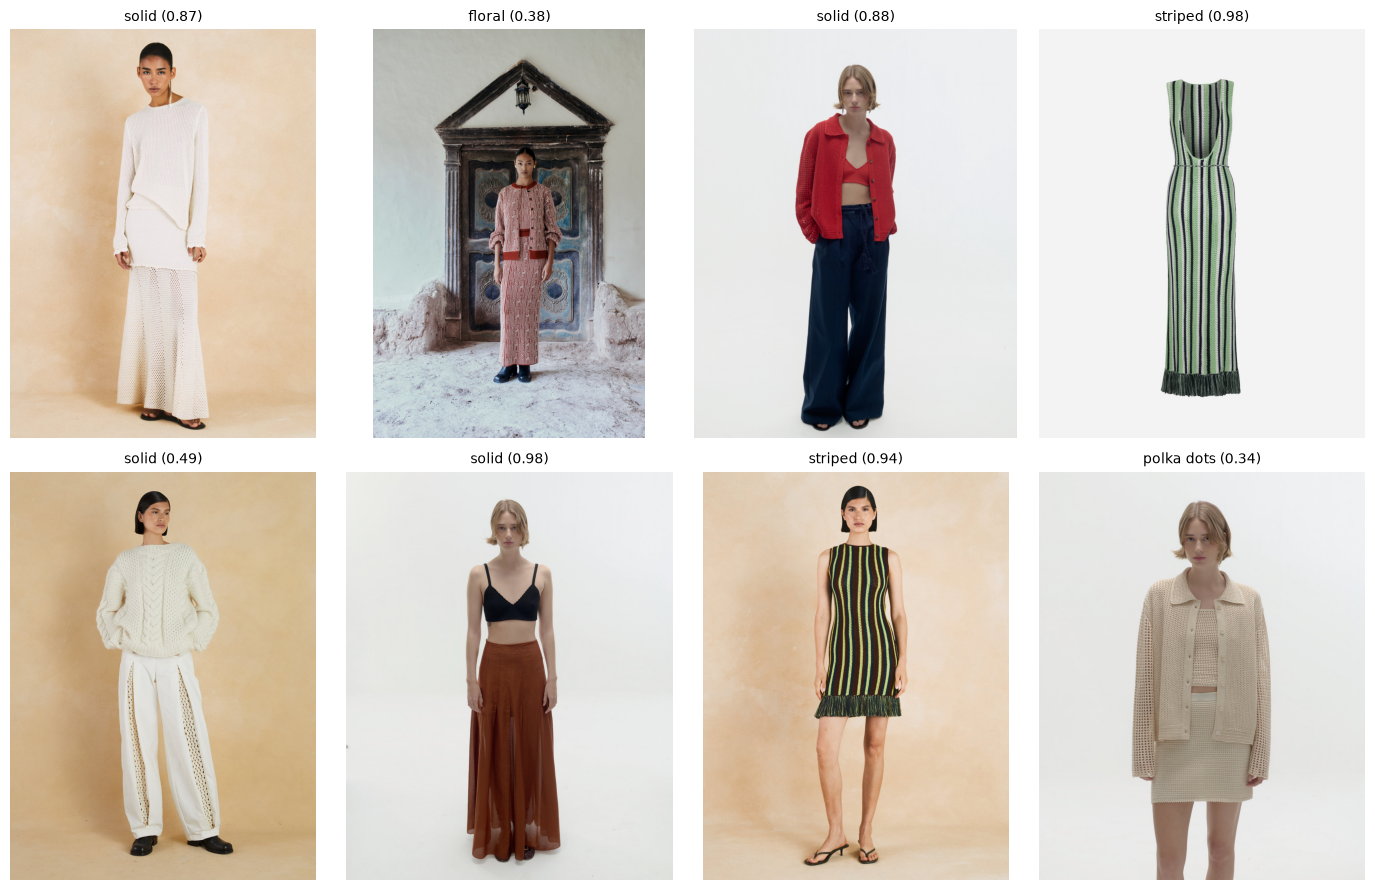

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

a = pd.read_csv(ROOT / "data/attributes.csv")
a = a[a["brand"] == "escvdo"].sample(8, random_state=1)

fig, axes = plt.subplots(2, 4, figsize=(14, 9))
for ax, r in zip(axes.flat, a.itertuples()):
    ax.imshow(Image.open(ROOT / "images" / r.folder / r.file).convert("RGB"))
    ax.set_title(f"{r.pattern} ({r.pattern_conf})", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd

a = pd.read_csv(ROOT / "data/attributes.csv")
a["pattern_final"] = a["pattern"].where(a["pattern_conf"] >= 0.5, "solid / other")

a.to_csv(ROOT / "data/attributes.csv", index=False)
pd.crosstab(a["brand"], a["pattern_final"], normalize="index").round(2)

pattern_final,animal print,checked,floral,polka dots,solid,solid / other,striped
brand,,,,,,,
chloe,0.03,0.00,0.15,0.02,0.33,0.47,0.00
escvdo,0.08,0.02,0.00,0.06,0.19,0.31,0.35
